# Olist E-Commerce: Multi-Table EDA and Power BI Data Prep

**Goal:** combine several raw tables into one analysis-ready dataset, find the key relationships between variables, visualise them, and export clean tables for Power BI.

**Dataset:** Brazilian E-Commerce Public Dataset by Olist (Kaggle): https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

Put all the CSV files in the same folder as this notebook (or in Colab's `/content` files area).

## 1. Setup and load data

In [4]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# Auto-detect the folder that contains the Olist CSV files
CANDIDATES = [Path("."), Path("/content"), Path("data"), Path("data/raw"), Path("dataset")]
DATA_DIR = next((p for p in CANDIDATES if (p / "olist_orders_dataset.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Olist CSV files not found. Upload them next to this notebook "
                            "(or set DATA_DIR manually).")
print("Using data from:", DATA_DIR.resolve())

OUT = Path("output")
(OUT / "figures").mkdir(parents=True, exist_ok=True)
(OUT / "powerbi_ready").mkdir(parents=True, exist_ok=True)

files = {
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "category_map": "product_category_name_translation.csv",
}
t = {name: pd.read_csv(DATA_DIR / f) for name, f in files.items()}
for name, df in t.items():
    print(f"{name:13s} {df.shape}")

Using data from: C:\Users\harsh\Desktop\New folder\dataset
orders        (99441, 8)
items         (112650, 7)
payments      (103886, 5)
reviews       (99224, 7)
customers     (99441, 5)
products      (32951, 9)
category_map  (71, 2)


## 2. Data profiling
Row counts, duplicates and missing values for every raw table.

In [2]:
rows = []
for name, df in t.items():
    rows.append({
        "table": name, "rows": len(df), "columns": df.shape[1],
        "duplicate_rows": int(df.duplicated().sum()),
        "cells_missing": int(df.isna().sum().sum()),
        "missing_pct": round(df.isna().sum().sum() / df.size * 100, 2),
    })
profile = pd.DataFrame(rows)
profile.to_csv(OUT / "data_profile.csv", index=False)
profile

,table,rows,columns,duplicate_rows,cells_missing,missing_pct
0,orders,99441,8,0,4908,0.62
1,items,112650,7,0,0,0.00
2,payments,103886,5,0,0,0.00
3,reviews,99224,7,0,145903,21.01
4,customers,99441,5,0,0,0.00
5,products,32951,9,0,2448,0.83
6,category_map,71,2,0,0,0.00


In [5]:
# Which columns have the most missing values?
missing = pd.concat({n: d.isna().sum() for n, d in t.items()}).rename("missing")
missing[missing > 0].sort_values(ascending=False)

reviews   review_comment_title             87656
          review_comment_message           58247
orders    order_delivered_customer_date     2965
          order_delivered_carrier_date      1783
products  product_category_name              610
          product_description_lenght         610
          product_name_lenght                610
          product_photos_qty                 610
orders    order_approved_at                  160
products  product_weight_g                     2
          product_length_cm                    2
          product_height_cm                    2
          product_width_cm                     2
Name: missing, dtype: int64

## 3. Cleaning and merging
Steps:
1. Parse dates and keep **delivered** orders with a delivery date
2. **Aggregate child tables to order level first**, so one-to-many joins do not duplicate rows and inflate revenue
3. Merge orders + customers + items + payments + reviews

In [6]:
orders = t["orders"].drop_duplicates("order_id").copy()
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c], errors="coerce")

print("Order status counts:")
print(orders["order_status"].value_counts())

orders = orders[(orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].notna()]
print("\nDelivered orders kept:", len(orders))

Order status counts:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Delivered orders kept: 96470


In [7]:
items_agg = (t["items"].groupby("order_id")
             .agg(n_items=("order_item_id", "count"),
                  n_sellers=("seller_id", "nunique"),
                  items_value=("price", "sum"),
                  freight_value=("freight_value", "sum"))
             .reset_index())

pay_agg = (t["payments"].groupby("order_id")
           .agg(payment_value=("payment_value", "sum"),
                max_installments=("payment_installments", "max"),
                payment_type=("payment_type", lambda s: s.mode().iat[0]))
           .reset_index())

rev_agg = t["reviews"].groupby("order_id").agg(review_score=("review_score", "mean")).reset_index()

fact_orders = (orders
               .merge(t["customers"][["customer_id", "customer_unique_id", "customer_state"]],
                      on="customer_id", how="left")
               .merge(items_agg, on="order_id", how="inner")
               .merge(pay_agg, on="order_id", how="left")
               .merge(rev_agg, on="order_id", how="left"))
print("fact_orders:", fact_orders.shape)

fact_orders: (96470, 18)


## 4. Feature engineering

In [8]:
fact_orders["delivery_days"] = (fact_orders["order_delivered_customer_date"] - fact_orders["order_purchase_timestamp"]).dt.days
fact_orders["delay_days"] = (fact_orders["order_delivered_customer_date"] - fact_orders["order_estimated_delivery_date"]).dt.days
fact_orders["is_late"] = (fact_orders["delay_days"] > 0).astype(int)
fact_orders["freight_ratio"] = fact_orders["freight_value"] / fact_orders["items_value"]
fact_orders["purchase_month"] = fact_orders["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()

# Remove clear data errors
before = len(fact_orders)
fact_orders = fact_orders[(fact_orders["delivery_days"] >= 0) & (fact_orders["items_value"] > 0)]
print(f"Removed {before - len(fact_orders)} invalid rows; {len(fact_orders):,} orders remain")

# Item-level table with product category (English names)
prod = t["products"].merge(t["category_map"], on="product_category_name", how="left")
prod["category"] = prod["product_category_name_english"].fillna("unknown")
fact_items = (t["items"]
              .merge(fact_orders[["order_id", "purchase_month", "review_score", "is_late"]], on="order_id", how="inner")
              .merge(prod[["product_id", "category", "product_weight_g", "product_photos_qty"]], on="product_id", how="left"))
print("fact_items:", fact_items.shape)
fact_orders.head()

Removed 0 invalid rows; 96,470 orders remain
fact_items: (110189, 13)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_state,n_items,n_sellers,items_value,freight_value,payment_value,max_installments,payment_type,review_score,delivery_days,delay_days,is_late,freight_ratio,purchase_month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,SP,1,1,29.99,8.72,38.71,1.0,voucher,4.0,8,-8,0,0.290764,2017-10-01
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,BA,1,1,118.70,22.76,141.46,1.0,boleto,4.0,13,-6,0,0.191744,2018-07-01
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,GO,1,1,159.90,19.22,179.12,3.0,credit_card,5.0,9,-18,0,0.120200,2018-08-01
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,RN,1,1,45.00,27.20,72.20,1.0,credit_card,5.0,13,-13,0,0.604444,2017-11-01
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,SP,1,1,19.90,8.72,28.62,1.0,credit_card,5.0,2,-10,0,0.438191,2018-02-01


## 5. Exploratory data analysis

### 5.1 Summary statistics and distributions

In [9]:
fact_orders[["items_value", "freight_value", "payment_value", "delivery_days", "delay_days", "review_score"]].describe().round(2)

,items_value,freight_value,payment_value,delivery_days,delay_days,review_score
count,96470.00,96470.00,96469.00,96470.00,96470.00,95824.00
mean,137.04,22.79,159.86,12.09,-11.88,4.16
std,209.05,21.56,218.82,9.55,10.18,1.28
min,0.85,0.00,9.59,0.00,-147.00,1.00
25%,45.90,13.85,61.88,6.00,-17.00,4.00
50%,86.50,17.17,105.28,10.00,-12.00,5.00
75%,149.90,24.02,176.33,15.00,-7.00,5.00
max,13440.00,1794.96,13664.08,209.00,188.00,5.00


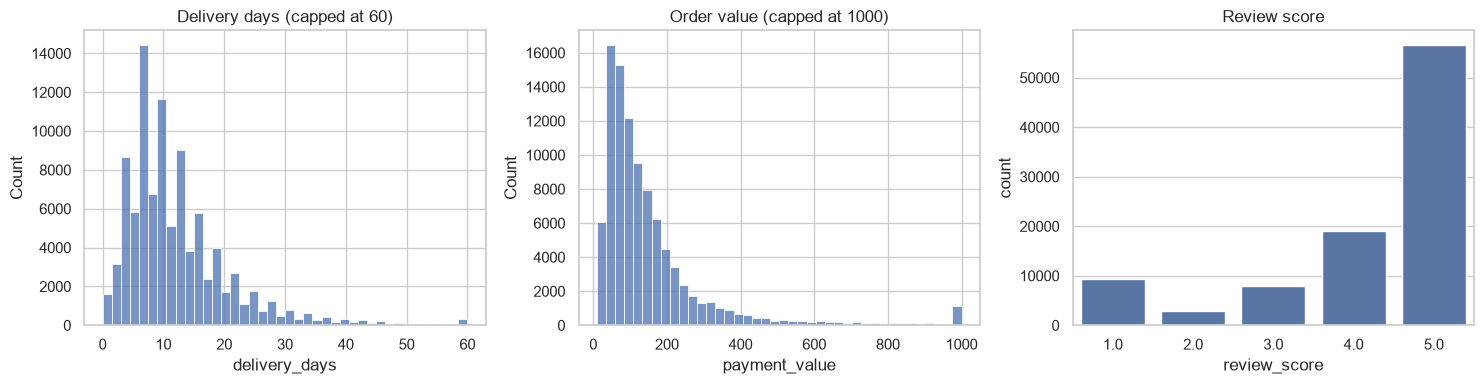

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(fact_orders["delivery_days"].clip(upper=60), bins=40, ax=ax[0]); ax[0].set_title("Delivery days (capped at 60)")
sns.histplot(fact_orders["payment_value"].clip(upper=1000), bins=40, ax=ax[1]); ax[1].set_title("Order value (capped at 1000)")
sns.countplot(x=fact_orders["review_score"].round(), ax=ax[2]); ax[2].set_title("Review score")
plt.tight_layout(); plt.savefig(OUT / "figures/00_distributions.png", dpi=150); plt.show()

### 5.2 Correlation between key metrics

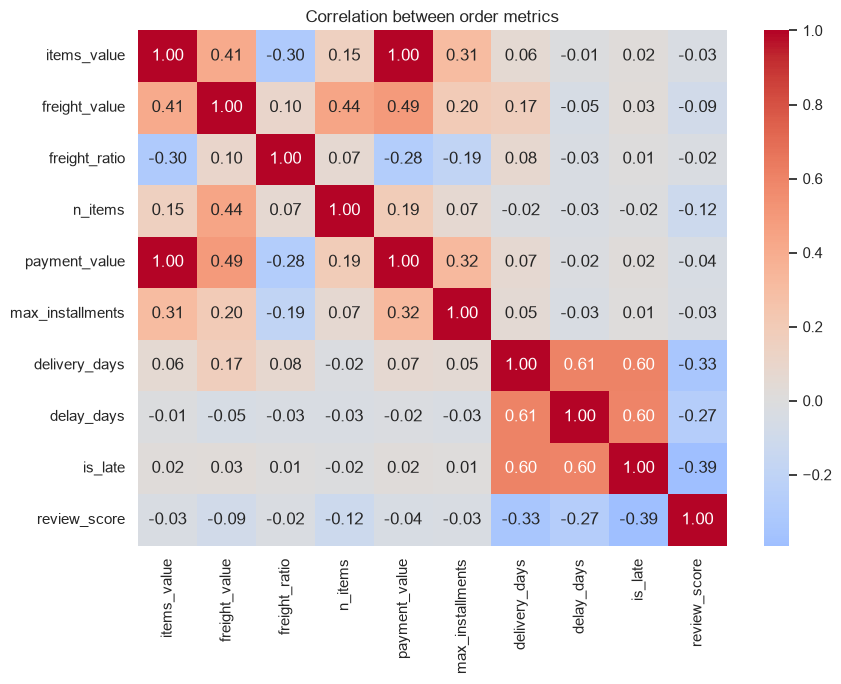

Strongest relationships with review_score:


is_late            -0.392
delivery_days      -0.334
delay_days         -0.267
n_items            -0.123
freight_value      -0.090
payment_value      -0.042
items_value        -0.035
max_installments   -0.031
freight_ratio      -0.024
Name: review_score, dtype: float64

In [11]:
num_cols = ["items_value", "freight_value", "freight_ratio", "n_items", "payment_value",
            "max_installments", "delivery_days", "delay_days", "is_late", "review_score"]
corr = fact_orders[num_cols].corr()
corr.to_csv(OUT / "correlation_matrix.csv")

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between order metrics")
plt.tight_layout(); plt.savefig(OUT / "figures/01_correlation_heatmap.png", dpi=150); plt.show()

print("Strongest relationships with review_score:")
corr["review_score"].drop("review_score").sort_values(key=abs, ascending=False).round(3)

### 5.3 Key relationship: late delivery vs customer satisfaction

is_late
On time    4.29
Late       2.27
Name: review_score, dtype: float64

Late delivery rate: 6.8%


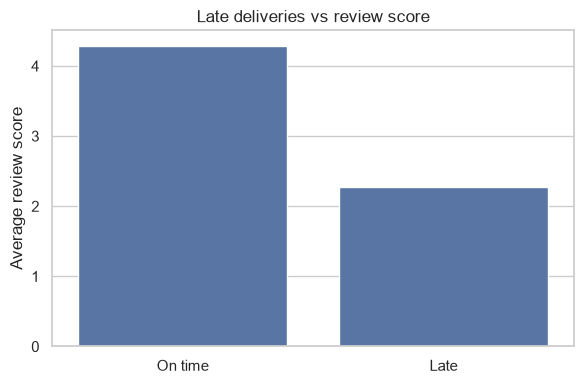

In [12]:
late = fact_orders.groupby("is_late")["review_score"].mean().rename({0: "On time", 1: "Late"})
print(late.round(2))
print(f"\nLate delivery rate: {fact_orders['is_late'].mean():.1%}")

plt.figure(figsize=(6, 4))
sns.barplot(x=late.index, y=late.values)
plt.ylabel("Average review score"); plt.xlabel(""); plt.title("Late deliveries vs review score")
plt.tight_layout(); plt.savefig(OUT / "figures/02_late_vs_review.png", dpi=150); plt.show()

### 5.4 Monthly revenue trend

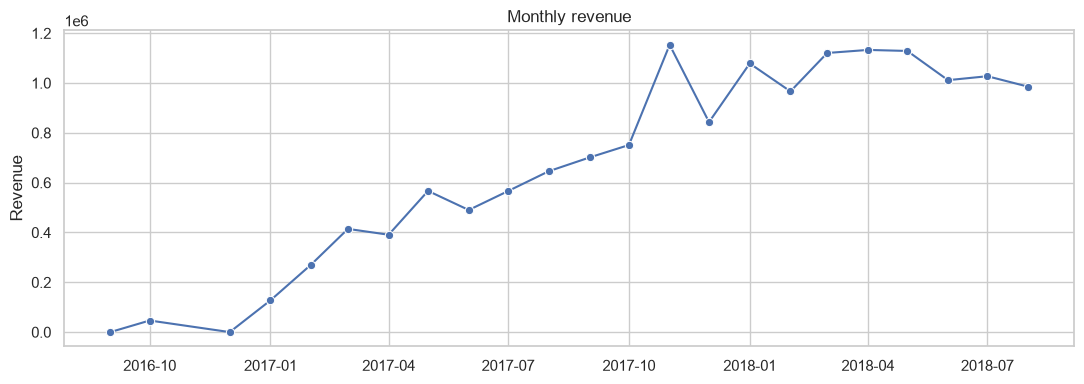

In [13]:
monthly = (fact_orders.groupby("purchase_month")
           .agg(orders=("order_id", "count"), revenue=("payment_value", "sum"), avg_review=("review_score", "mean"))
           .reset_index())
monthly.to_csv(OUT / "monthly_summary.csv", index=False)

plt.figure(figsize=(11, 4))
sns.lineplot(data=monthly, x="purchase_month", y="revenue", marker="o")
plt.title("Monthly revenue"); plt.xlabel(""); plt.ylabel("Revenue")
plt.tight_layout(); plt.savefig(OUT / "figures/03_monthly_revenue.png", dpi=150); plt.show()

### 5.5 Product categories (Pareto view)

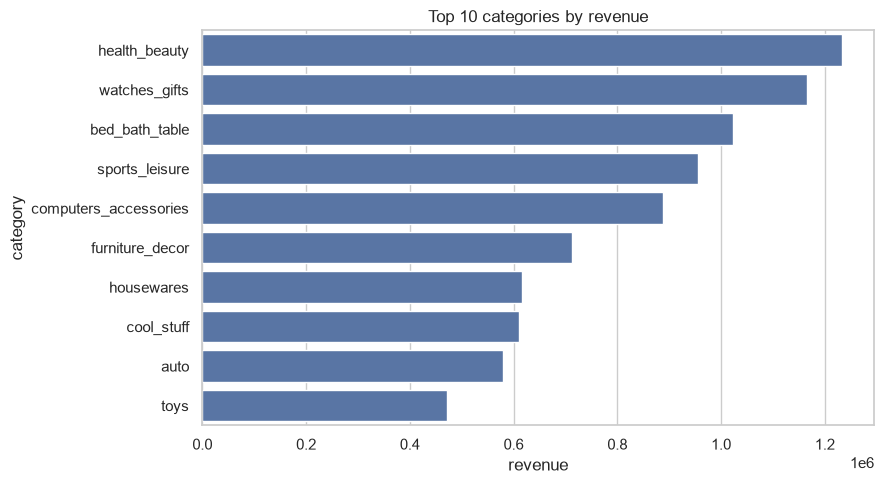

18 of 72 categories generate about 80% of revenue


,category,revenue,orders,avg_review,revenue_share_pct,cumulative_share_pct
0,health_beauty,1233131.72,8647,4.189729,9.327598,9.327598
1,watches_gifts,1165898.98,5493,4.071392,8.819040,18.146638
2,bed_bath_table,1023434.76,9272,3.923968,7.741418,25.888056
3,sports_leisure,954673.55,7529,4.165393,7.221298,33.109354
4,computers_accessories,888613.62,6529,3.986854,6.721610,39.830964
5,furniture_decor,711927.69,6307,3.953775,5.385131,45.216095
6,housewares,615628.69,5743,4.107904,4.656710,49.872805
7,cool_stuff,610204.10,3559,4.194904,4.615678,54.488483
8,auto,578849.35,3809,4.115788,4.378506,58.866989
9,toys,471097.49,3803,4.208729,3.563454,62.430443


In [14]:
cat = (fact_items.groupby("category")
       .agg(revenue=("price", "sum"), orders=("order_id", "nunique"), avg_review=("review_score", "mean"))
       .sort_values("revenue", ascending=False).reset_index())
cat["revenue_share_pct"] = cat["revenue"] / cat["revenue"].sum() * 100
cat["cumulative_share_pct"] = cat["revenue_share_pct"].cumsum()
cat.to_csv(OUT / "category_summary.csv", index=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=cat.head(10), y="category", x="revenue")
plt.title("Top 10 categories by revenue")
plt.tight_layout(); plt.savefig(OUT / "figures/04_top_categories.png", dpi=150); plt.show()

n80 = int((cat["cumulative_share_pct"] < 80).sum() + 1)
print(f"{n80} of {len(cat)} categories generate about 80% of revenue")
cat.head(10)

### 5.6 Delivery performance by customer state

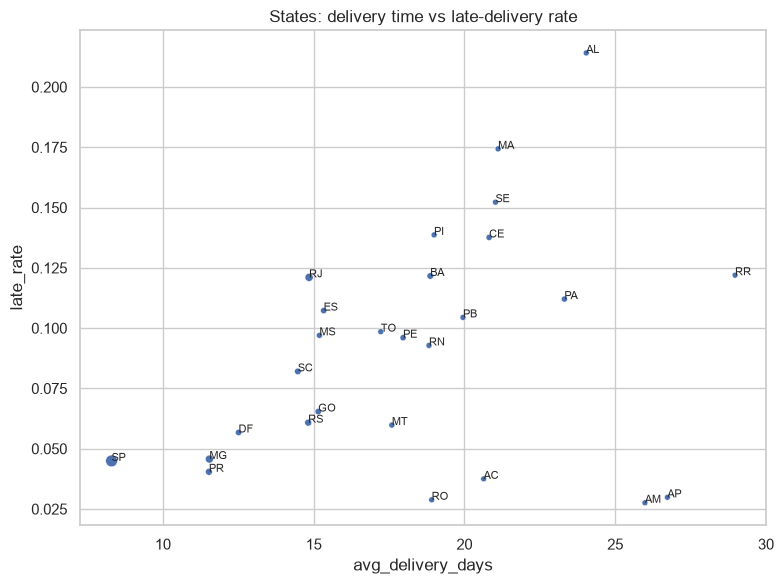

,customer_state,orders,revenue,avg_delivery_days,late_rate,avg_review
21,RR,41,9039.52,28.975610,0.121951,3.902439
3,AP,67,16141.81,26.731343,0.029851,4.242424
2,AM,145,27596.18,25.986207,0.027586,4.243056
1,AL,397,94195.79,24.040302,0.214106,3.852792
13,PA,946,212027.55,23.316068,0.112051,3.909968


In [15]:
state = (fact_orders.groupby("customer_state")
         .agg(orders=("order_id", "count"), revenue=("payment_value", "sum"),
              avg_delivery_days=("delivery_days", "mean"), late_rate=("is_late", "mean"),
              avg_review=("review_score", "mean")).reset_index())
state.to_csv(OUT / "state_summary.csv", index=False)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=state, x="avg_delivery_days", y="late_rate", size="orders", legend=False)
for _, r in state.iterrows():
    plt.annotate(r["customer_state"], (r["avg_delivery_days"], r["late_rate"]), fontsize=8)
plt.title("States: delivery time vs late-delivery rate")
plt.tight_layout(); plt.savefig(OUT / "figures/05_state_delivery.png", dpi=150); plt.show()
state.sort_values("avg_delivery_days", ascending=False).head(5)

### 5.7 Payment behaviour

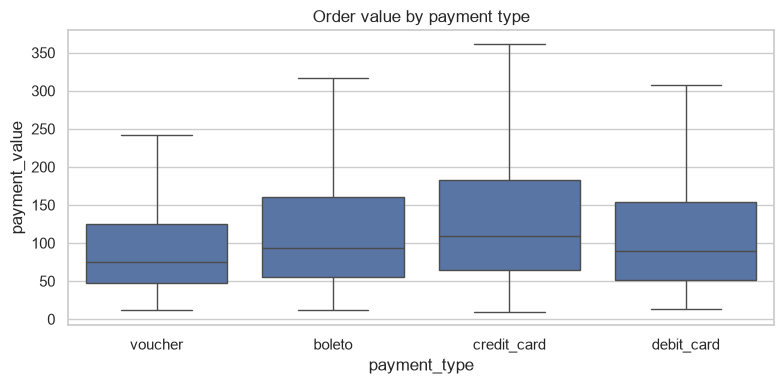

In [16]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=fact_orders, x="payment_type", y="payment_value", showfliers=False)
plt.title("Order value by payment type")
plt.tight_layout(); plt.savefig(OUT / "figures/06_payment_type.png", dpi=150); plt.show()

## 6. Key findings
- **Late delivery has the strongest relationship with customer satisfaction:** orders delivered on time average **4.29** in review score, while late orders average **2.27**. Late delivery affects **6.8%** of delivered orders and is the largest negative correlate of review score (**r = -0.39**).
- **Delivery time also matters, but less strongly:** review score is negatively correlated with delivery_days (**r = -0.33**) and delay_days (**r = -0.27**). Item value, freight value, payment value, number of items, and freight ratio show weak relationships with review score.
- **Revenue is concentrated in a small set of categories:** the top 10 categories contribute **62.43%** of revenue. Health & beauty leads at **R$1.233 million (9.33%)**, followed by watches/gifts (**R$1.166 million, 8.82%**) and bed/bath/table (**R$1.023 million, 7.74%**). The top five categories account for **39.83%** of revenue.
- **Delivery performance varies substantially by state:** RR, AP, AM, AL, and PA are the five slowest states, averaging approximately **29.0, 26.7, 26.0, 24.0, and 23.3 delivery days**, respectively. São Paulo is much faster at **8.30 days** and is the largest order market, with **40,494** orders.
- **Revenue and order activity increased strongly through 2017 and remained high in 2018:** November 2017 generated the highest monthly revenue (**R$1.153 million**), followed by April and May 2018 (about **R$1.133 million** and **R$1.129 million**). The November 2017 peak also coincided with an average review score of **3.99**, lower than the overall average of **4.16**.
- **Credit card is the dominant payment method:** it accounts for **73,934** orders and has a median order value of **R$108.86**. Boleto follows with **19,191** orders and a median of **R$93.78**; debit card and voucher are smaller segments.
- **Data quality is generally strong:** no duplicate rows are present in the raw tables, and the delivered-order fact table contains **96,470** orders. Missing values are concentrated mainly in operational date and review text fields, while the product table has missing product measurements.

## 7. Export clean tables for Power BI

In [17]:
fact_orders.to_csv(OUT / "powerbi_ready/fact_orders.csv", index=False)
fact_items.to_csv(OUT / "powerbi_ready/fact_order_items.csv", index=False)
state.to_csv(OUT / "powerbi_ready/state_summary.csv", index=False)
monthly.to_csv(OUT / "powerbi_ready/monthly_summary.csv", index=False)
cat.to_csv(OUT / "powerbi_ready/category_summary.csv", index=False)
print("Saved to:", (OUT / "powerbi_ready").resolve())
os.listdir(OUT / "powerbi_ready")

Saved to: C:\Users\harsh\Desktop\New folder\output\powerbi_ready


['category_summary.csv',
 'fact_orders.csv',
 'fact_order_items.csv',
 'monthly_summary.csv',
 'state_summary.csv']